# expex quickstart

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/davidesartor/expex/blob/main/examples/notebooks/quickstart.ipynb)

> **Python 3.14+ is needed.** expex requires Python 3.14, and Colab's hosted runtimes ship
> Python 3.12 (the 2026.01 runtime has 3.12.12), so on a hosted runtime the setup cell stops
> with a message. To run this notebook in Colab, start Jupyter on Python 3.14 on your machine
> and use *Connect → Connect to a local runtime*
> ([how](https://github.com/davidesartor/expex/blob/main/examples/notebooks/README.md#running-in-colab)),
> or open it in Jupyter directly. If *Runtime → Change runtime type* offers a runtime with
> Python 3.14, that works too. The outputs below are from a run on a CPU.

**Write the shapes in the signature; get checks, proofs, loops and model tools for free.**

expex is a thin layer over JAX. Annotate arrays with their sizes and the library reads those
annotations: it checks every call, proves the shapes for every size, turns plain Python loops
into `lax.scan`, and draws, costs and debugs your model. It is still JAX underneath: `jax.jit`
and `jax.grad` work as usual, and a compiled call costs the same as plain `jax.jit`.

This notebook runs the examples of the [README](../../README.md). The ported projects have a
notebook each: see [the list](README.md).

In [1]:
# Setup: install expex from GitHub (or use a local checkout) and fetch the examples.
EXPEX_REF = "main"  # the branch or tag of github.com/davidesartor/expex to install

import os, pathlib, subprocess, sys

if sys.version_info < (3, 14):
    raise RuntimeError(
        f"expex needs Python 3.14+, and this runtime has Python {sys.version.split()[0]}: "
        "connect to a local runtime with Python 3.14 (see the note at the top of the notebook)"
    )


def find_checkout() -> pathlib.Path | None:
    """A local checkout of expex: $EXPEX_REPO, or a folder above the working directory."""
    if os.environ.get("EXPEX_REPO"):
        return pathlib.Path(os.environ["EXPEX_REPO"]).resolve()
    for folder in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (folder / "src" / "expex").is_dir() and (folder / "examples").is_dir():
            return folder
    return None


def run(*cmd: str) -> None:
    subprocess.run(cmd, check=True)


REPO = find_checkout()
if REPO is None:  # Colab, or a notebook opened on its own: install from GitHub
    REPO = pathlib.Path("expex").resolve()
    run(sys.executable, "-m", "pip", "install", "-q", f"git+https://github.com/davidesartor/expex@{EXPEX_REF}")
    if not REPO.exists():  # the examples and the reference outputs of the originals
        run("git", "clone", "-q", "--depth", "1", "--branch", EXPEX_REF, "https://github.com/davidesartor/expex", str(REPO))
else:
    try:
        import expex  # noqa: F401
    except ImportError:
        run(sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO))
sys.path.insert(0, str(REPO / "examples"))
print("Python", sys.version.split()[0], "| examples from", REPO.name)

Python 3.14.6 | examples from vigilant-barnacle


In [2]:
import time

import jax
import jax.numpy as jnp
import jax.random as jr
import numpy as np

import expex
from expex import f32

key = jr.key(0)

## Shapes are checked, not commented

Sizes are type parameters (`[B, T, S, D]`), and arrays are annotated with them. A wrong call
says which axis is wrong and where its size came from:

In [3]:
@expex.fn
def attend[B, T, S, D](q: f32[B, T, D], k: f32[B, S, D]) -> f32[B, T, S]:
    return expex.einsum(q, k, to=(B, T, S))


print(attend(jnp.ones((2, 3, 4)), jnp.ones((2, 5, 4))).shape)
try:
    attend(jnp.ones((2, 3, 4)), jnp.ones((5, 3, 4)))
except expex.ShapeError as e:
    error = e
error

(2, 3, 5)
ShapeError: attend(): argument `k` does not match its annotation.

    declared  k: f32[B, S, D]
    received     f32[5, 3, 4]

    B is 2 (from `q: f32[2, 3, 4]`), but axis 0 of `k` is 5.

    attend[B, T, S, D](q: f32[B, T, D], k: f32[B, S, D]) -> f32[B, T, S]
    defined at /tmp/ipykernel_3636/3563913166.py:1
  see https://github.com/davidesartor/expex/blob/main/docs/errors.md#ex101


## Loops are loops, branches are `if` / `else`

A `for` over a size becomes a `lax.scan` carrying what the body updates; an `if` on a traced
value becomes a select (or a `lax.cond`). A function written for one number is called on arrays:

In [4]:
@expex.fn
def rnn[T, D](w: f32[D, D], xs: f32[T, D]) -> f32[T, D]:
    h, hs = jnp.zeros(D), []
    for t in range(T):  # a lax.scan carrying h
        h = jnp.tanh(w @ h + xs[t])
        hs.append(h)
    return jnp.asarray(hs)


@expex.fn(jit=True)
def safe_log(x: f32) -> f32:  # written for one number, called on arrays
    return jnp.log(x) if x > 0 else -jnp.inf  # a select per element


print(jax.jit(rnn)(0.1 * jr.normal(key, (8, 8)), jnp.ones((20, 8))).shape)
print("how the loop ran:", rnn.flow)
print(safe_log(jnp.array([2.0, 0.0, -1.0])))

(20, 8)
how the loop ran: {4: 'for -> lax.scan (carries h)'}
[0.6931472      -inf      -inf]


## Models are classes; identical layers scan themselves; batches map themselves

A struct is built from its annotations (a key first, then the sizes). The loop over identical
blocks is one `lax.scan`, and a model written for one example maps over a batch:

In [5]:
@expex.struct
class Block[D]:
    w: f32[D, D] = jax.nn.initializers.normal(0.1)
    b: f32[D] = 0.0

    def __call__(self, x: f32[D]) -> f32[D]:
        y = self.w @ x + self.b
        return x + jax.nn.gelu(y)


@expex.struct
class Stack[D]:
    blocks: list[Block[D]]

    def __call__(self, x: f32[D]) -> f32[D]:
        for block in self.blocks:  # identical layers: one lax.scan
            x = block(x)
        return x


model = Stack(key, D=64, blocks=12)
ys = model(jnp.ones((8, 64)))  # extra leading axes are mapped over
print(ys.shape)
model

(8, 64)


Stack[D=64]   49,920 parameters · 200 kB
  blocks      list[12]                49,920
    [0]       Block[D=64]  Block[D]    4,160
      w       f32[64, 64]  f32[D, D]   4,096
      b       f32[64]      f32[D]         64
    [1]       Block[D=64]  Block[D]    4,160
      w       f32[64, 64]  f32[D, D]   4,096
      b       f32[64]      f32[D]         64
    [2]       Block[D=64]  Block[D]    4,160
      w       f32[64, 64]  f32[D, D]   4,096
      b       f32[64]      f32[D]         64
    ⋯ 8 more
    [11]      Block[D=64]  Block[D]    4,160
      w       f32[64, 64]  f32[D, D]   4,096
      b       f32[64]      f32[D]         64

## What else the annotations give you

**Proofs for every size**, without data:

In [6]:
expex.prove(Stack.__call__)

__main__.Stack.__call__: proved for all sizes

**Cost as formulas in the sizes**, or as numbers for given sizes:

In [7]:
print(expex.cost(Stack.__call__))
print(expex.cost(Stack.__call__, D=1024, blocks=24))

Stack.__call__   (sizes: D, L)
  flops        2·D²·L + 10·D·L
  parameters   D²·L + D·L
  largest      f32[D] (D elements)
  note: L = len(self.blocks)
Stack.__call__   (sizes: D=1024, L=24)
  flops        50577408   = 50.6 MFLOP
  parameters   25190400   = 25.2 M
  largest      f32[D] (1024 elements)
  note: L = len(self.blocks)


**Changing part of a model**, checked against its annotation, and **model summaries**:

In [8]:
edited = model.at.blocks[5].w.multiply(0.5)  # a copy with one block's weights scaled
edited = edited.at.blocks[0].b.set(jnp.ones(64))  # also .add, .apply(f), .get()
try:
    model.at.blocks[0].b.set(jnp.ones(63))
except expex.ShapeError as e:
    print(e)
expex.summary(model)

Stack.at.blocks[0].b.set(...): `blocks[0].b` is f32[63], but is declared f32[D].

    D is 64 (from `blocks[1].w: f32[64, 64]`), but axis 0 of `blocks[0].b` is 63.
  see https://github.com/davidesartor/expex/blob/main/docs/errors.md#ex308


Stack   (D=64, L=12)
module     class              params  formula       bytes   flops  flops formula
────────────────────────────────────────────────────────────────────────────────
blocks[*]  Block[D=64]  × 12   4,160  D² + D      16.6 kB  8.83 k  2·D² + 10·D
  w        f32[D, D]           4,096  D²          16.4 kB
  b        f32[D]                 64  D             256 B
────────────────────────────────────────────────────────────────────────────────
total      Stack              49,920  D²·L + D·L   200 kB   106 k  2·D²·L + 10·D·L
note: L = len(blocks)

**Architecture diagrams**, drawn from the code. Here the small transformer of
[`examples/transformer.py`](../transformer.py). When you run the notebook it is an interactive
page: click a call to open it, hover for its signature.

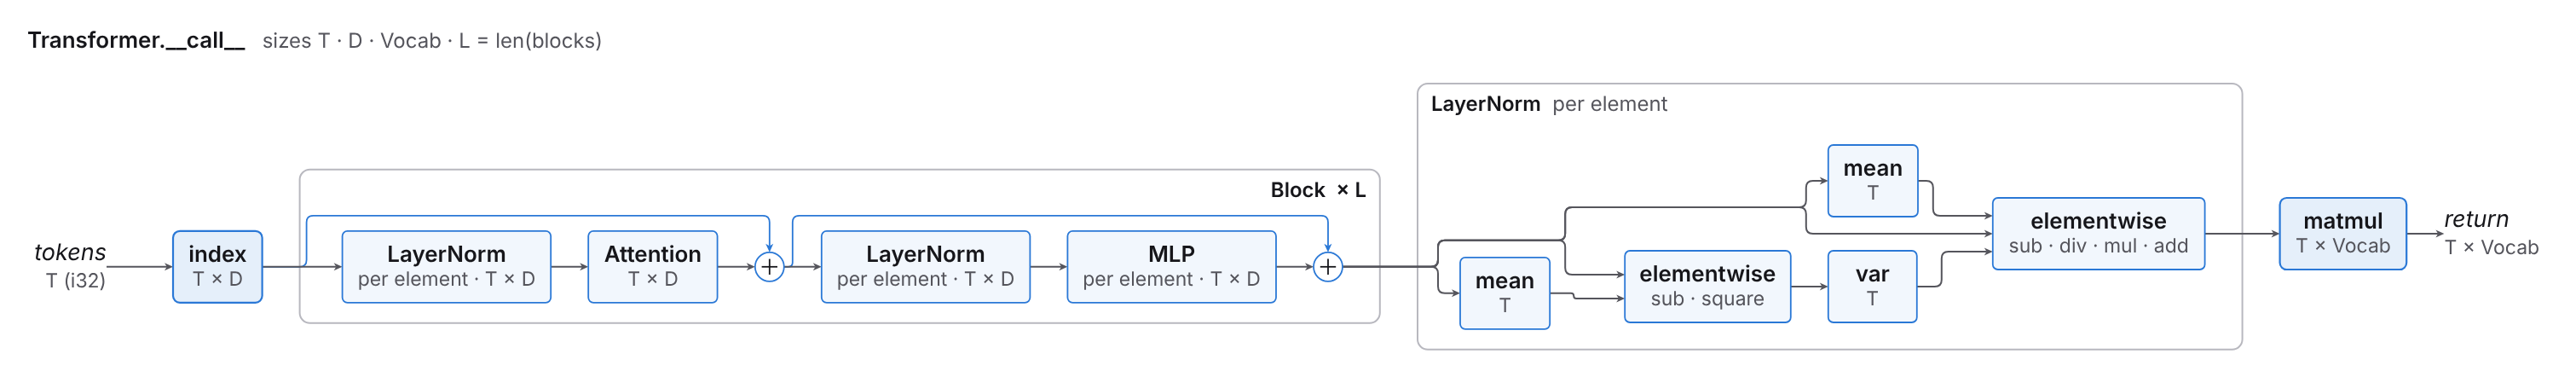

In [9]:
from transformer import Transformer  # examples/transformer.py

expex.diagram(Transformer.__call__, depth=2)

The same diagram timed on real inputs, each call coloured by its share of the measured time:

Transformer.__call__   measured with jax.profiler (CPU): 238 µs of XLA op time per call (summed over threads), 248 µs wall, median of 5 runs
  × 4                                      227 µs   95.6%  ███████████████████
    Block.__call__                         227 µs   95.6%  ███████████████████
      LayerNorm.__call__ · vectorized     15.7 µs    6.6%  █
      Attention.__call__                   149 µs   62.7%  █████████████
        Attention.split                   4.18 µs    1.8%
        Attention.split                   3.27 µs    1.4%
        Attention.split                   2.65 µs    1.1%
        Attention.causal · vectorized     82.4 µs   34.6%  ███████
      LayerNorm.__call__ · vectorized     15.8 µs    6.6%  █
      MLP.__call__ · vectorized           40.6 µs   17.1%  ███
  LayerNorm.__call__ · vectorized         3.58 µs    1.5%
  (outside the calls)                     6.91 µs    2.9%


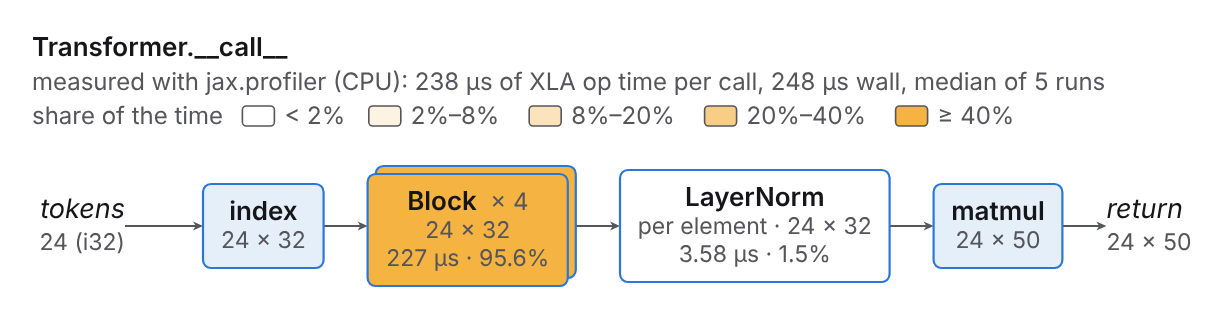

In [10]:
lm = Transformer(key, Vocab=50, D=32, F=64, blocks=4, heads=4)
tokens = jr.randint(jr.key(1), (24,), 0, 50)
timed = expex.diagram.timed(lm.__call__, tokens)
print(timed.text)
timed

A `ShapeError` raised inside a model carries a diagram of the trace up to the call that
failed, with that call and the path into it in red:

ShapeError: Stack.__call__(): argument `x` does not match its annotation, even with the extra leading axes mapped over.

    declared  x: f32[D]
    received     f32[15]  (one element)

    D is 16 (from `self.blocks[0].w: f32[16, 16]`), but axis 0 of `x` is 15.

    Extra leading axes are mapped over automatically: `x: f32[4, 15]` is a batch [4] of f32[D].

    __call__(self: Stack, x: f32[D]) -> f32[D]
    defined at /tmp/ipykernel_3636/1771243200.py:15
  see https://github.com/davidesartor/expex/blob/main/docs/errors.md#ex101
expex: in Probe.__call__(self: Probe, x: f32[4, 16])  [D=16, B=4]


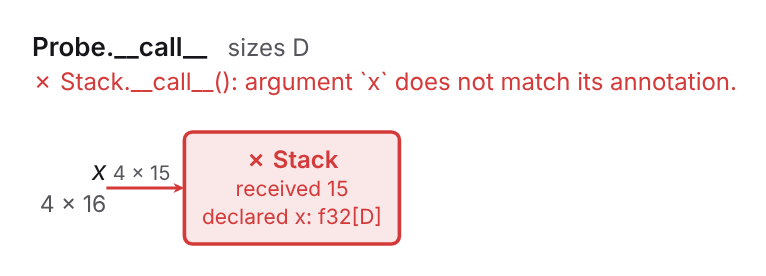

In [11]:
@expex.struct
class Probe[D]:
    stack: Stack[D]
    w: f32[D] = 1.0

    def __call__[B](self, x: f32[B, D]) -> f32[B]:
        return self.stack(x[:, 1:]) @ self.w  # a bug: x loses a feature


probe = Probe(jr.key(1), D=16, blocks=2)
try:
    probe(jnp.ones((4, 16)))
except expex.ShapeError as e:
    error = e
error

**`expex.inspect`** puts every tool in one page, over the module tree: summary, diagram, cost,
activations and gradients of a loss, and the FLOPs per source line.

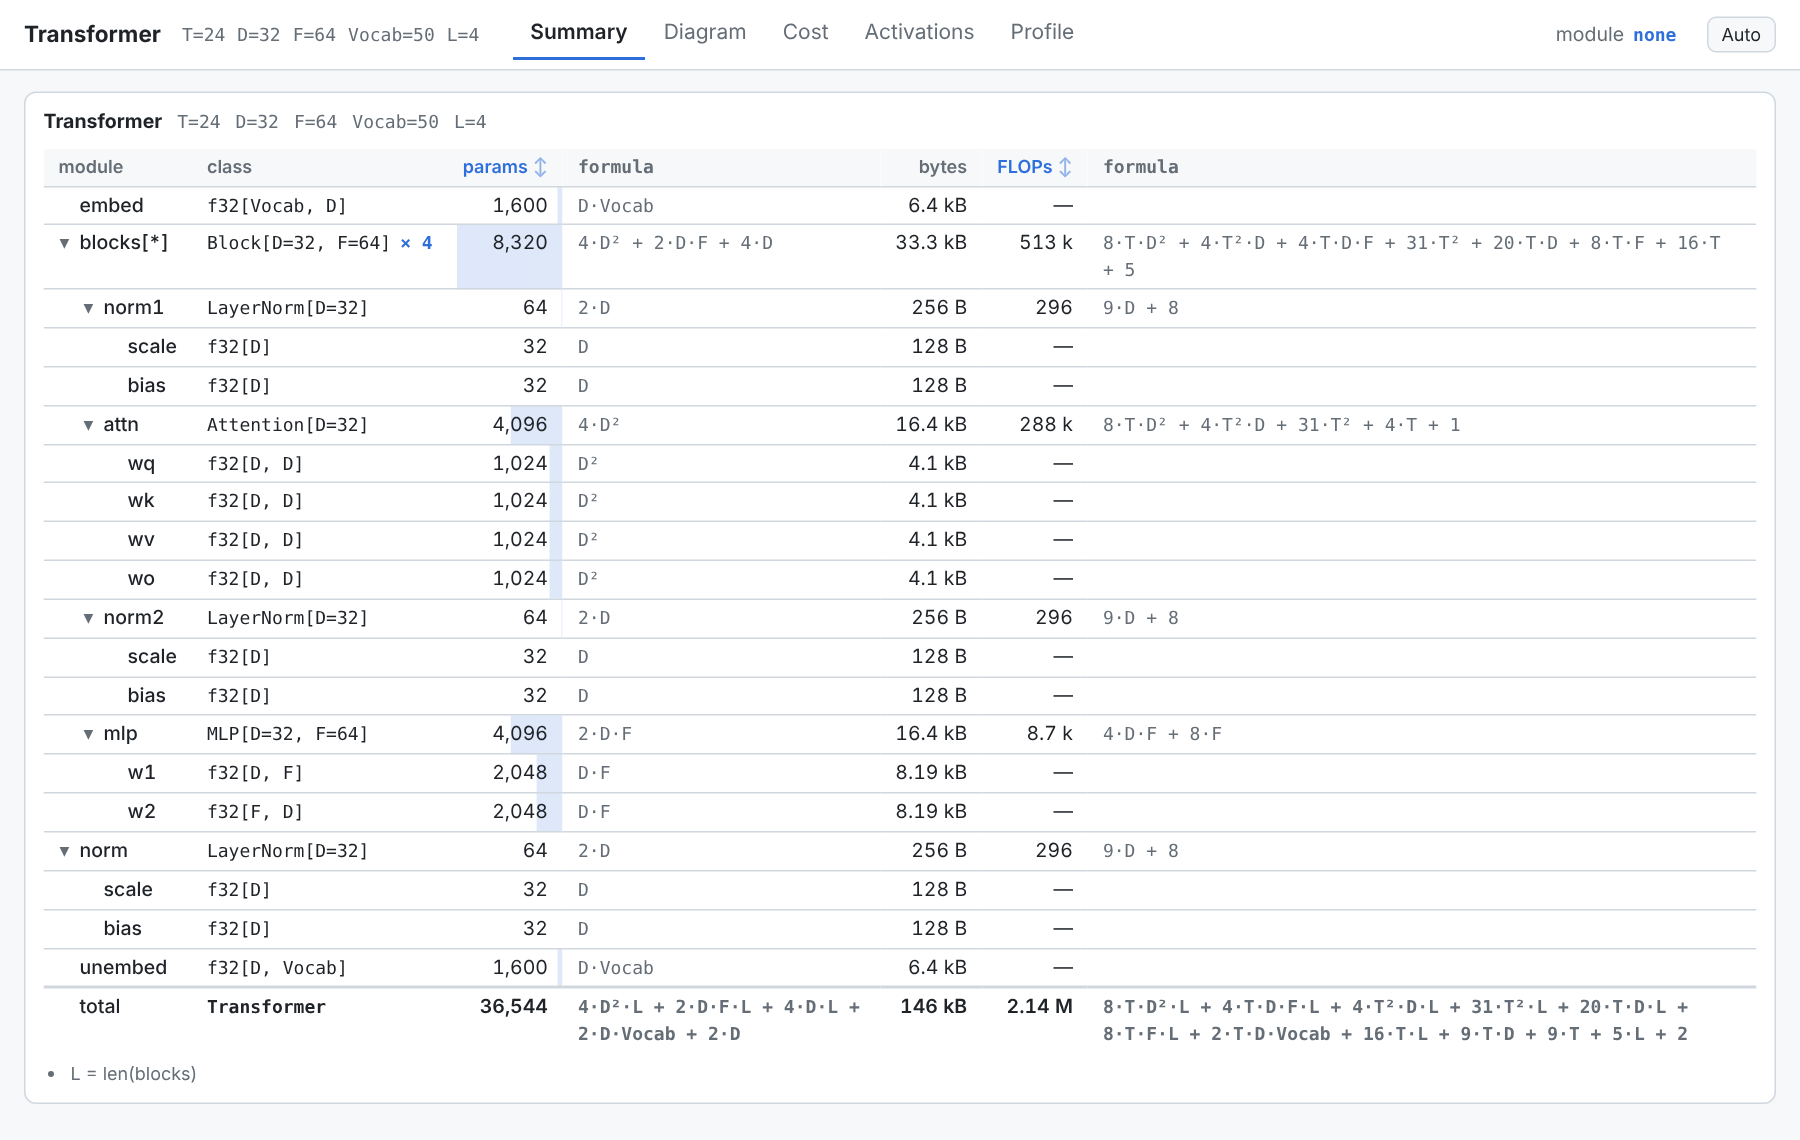

In [12]:
expex.inspect(lm, tokens, loss=lambda m, t: m.loss(t))

## Debugging

Shapes line by line, and where a NaN first appeared:

In [13]:
print(expex.debug.shapes(Block.__call__))


@expex.fn
def entropy[N](logits: f32[N]) -> f32:
    p = jax.nn.softmax(logits)
    return -(p * jnp.log(p)).sum()


print(expex.debug.find_nan(entropy, jnp.array([0.0, 200.0, -200.0])))

__call__(self: Block, x: f32[D]) -> f32[D]   [symbolic D]
    6 |     def __call__(self, x: f32[D]) -> f32[D]:
    7 |         y = self.w @ x + self.b     # y: f32[D]
    8 |         return x + jax.nn.gelu(y)   # -> f32[D]


NaN first appears at /tmp/ipykernel_3636/2879642664.py:7 (entropy)
    > return -(p * jnp.log(p)).sum()
  operation: mul
  inputs:
    #0: f32[3]  min=0  max=1  (2 zero, of 3)
    #1: f32[3]  min=0  max=0  (2 -inf, 1 zero, of 3)
  output:
    f32[3]  min=0  max=0  (2 nan, 1 zero, of 3)
  infinities appeared earlier at:
    /tmp/ipykernel_3636/2879642664.py:7 (entropy)  (log)  > return -(p * jnp.log(p)).sum()


Activations and gradients of every layer, flagging exploding or dead ones. Here one block's
weights are scaled by 1000:

In [14]:
x = jr.normal(jr.key(1), (8, 64))
broken = model.at.blocks[5].w.multiply(1e3)
watch = expex.debug.watch(lambda m: (m(x) ** 2).mean(), broken, growth=10.0)
for row in watch.flagged:
    print(f"{row.name:20} {'; '.join(row.flags)}")
watch

blocks[0].__call__   gradient exploding: RMS 1.9e+03× the layers' median
blocks[1].__call__   gradient exploding: RMS 1.7e+03× the layers' median
blocks[2].__call__   gradient exploding: RMS 1.4e+03× the layers' median
blocks[3].__call__   gradient exploding: RMS 1.1e+03× the layers' median
blocks[4].__call__   gradient exploding: RMS 9e+02× the layers' median
blocks[5].__call__   activations growing: RMS ×4.6e+02 from blocks[4].__call__


watch <lambda>: loss 3.68993e+07, 13 calls, 6 flagged  (grad_ratio=100.0, growth=10.0)
                                       ─────────────────────output────────────────────  ───────────────d loss / d output───────────────
   call                   shape    ×n      mean       std     |max|       rms  nan/inf      mean       std     |max|       rms  nan/inf  flags
   Stack.__call__         f32[64]   8  4.95e+03  3.52e+03  2.43e+04  6.07e+03               19.3      13.8        95      23.7
!    blocks[0].__call__   f32[64]   8     0.184      1.15      5.35      1.16           3.78e+04  3.27e+05  1.43e+06   3.3e+05           gradient exploding: RMS 1.9e+03× the layers' median
!    blocks[1].__call__   f32[64]   8     0.409      1.24      5.74      1.31           3.04e+04  2.81e+05  1.26e+06  2.83e+05           gradient exploding: RMS 1.7e+03× the layers' median
!    blocks[2].__call__   f32[64]   8      0.71      1.44       6.6       1.6           3.53e+04  2.29e+05  1.32e+06  2.32e+05   

## Porting existing JAX code

`expex.annotate` runs a plain function on examples and proposes its annotated signature, with
sizes grouped by the dataflow:

In [15]:
def attend_jax(q, k, v):
    scores = jnp.einsum("btd,bsd->bts", q, k) / jnp.sqrt(q.shape[-1])
    return jax.nn.softmax(scores, axis=-1) @ v


print(expex.annotate(attend_jax, jnp.ones((2, 3, 8)), jnp.ones((2, 5, 8)), jnp.ones((2, 5, 4))))

def attend_jax[B, T, S, D, A](q: f32[B, T, D], k: f32[B, S, D], v: f32[B, S, A]) -> f32[B, T, A]:

sizes in the example: B=2, T=3, S=5, D=8, A=4


## Speed

A compiled call costs the same as plain `jax.jit`: the checks run once, while tracing. Here the
12-block stack on a batch of 256, compiled by expex (`@expex.fn(jit=True)`) and by `jax.jit` on
the same function, and the plain JAX version of the README (stacked weights, `lax.scan`, `vmap`).
Timings depend on the machine.

In [16]:
def bench(f, *args, n=50):
    """Median seconds per call, after a first call that compiles."""
    jax.block_until_ready(f(*args))
    times = []
    for _ in range(n):
        start = time.perf_counter()
        jax.block_until_ready(f(*args))
        times.append(time.perf_counter() - start)
    return float(np.median(times))


@expex.fn(jit=True)
def run_stack[B, D](model: Stack[D], x: f32[B, D]) -> f32[B, D]:
    return model(x)


def plain(params, x):  # the README's JAX version
    def layer(x, p):
        return x + jax.nn.gelu(p["w"] @ x + p["b"]), None

    return jax.lax.scan(layer, x, params)[0]


params = {"w": jnp.stack([b.w for b in model.blocks]), "b": jnp.stack([b.b for b in model.blocks])}
batch = jr.normal(jr.key(2), (256, 64))
print(f"@expex.fn(jit=True)   {bench(run_stack, model, batch) * 1e6:8.1f} µs")
print(f"jax.jit(model call)   {bench(jax.jit(lambda m, x: m(x)), model, batch) * 1e6:8.1f} µs")
print(f"plain JAX (scan+vmap) {bench(jax.jit(jax.vmap(plain, in_axes=(None, 0))), params, batch) * 1e6:8.1f} µs")

@expex.fn(jit=True)      415.7 µs
jax.jit(model call)      393.5 µs


plain JAX (scan+vmap)    384.6 µs
